In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/sample_submission.csv
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/test.zip


In [2]:
import os
import glob
import zipfile
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
# =========================================================
# 1. Zip Extraction & Dataset Preparation
# =========================================================
possible_paths = [
    "/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip",
    "/kaggle/input/dogs-vs-cats-redux-kernels-edition/train.zip",
    "../input/dogs-vs-cats-redux-kernels-edition/train.zip",
    "./train.zip"
]

zip_path = next((p for p in possible_paths if os.path.exists(p)), None)
if zip_path is None:
    raise FileNotFoundError("Could not find train.zip. Check your Kaggle dataset input path.")

extract_dir = "/kaggle/working/train_extracted"
if not os.path.exists(extract_dir):
    print(f"Unzipping {zip_path} into {extract_dir}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
else:
    print(f"Directory {extract_dir} already exists. Skipping extraction.")

img_dir = extract_dir
sub_train = os.path.join(extract_dir, "train")
if os.path.exists(sub_train):
    img_dir = sub_train

class KaggleReduxCatsDogs(Dataset):
    def __init__(self, folder_path):
        self.files = sorted(glob.glob(os.path.join(folder_path, "*.jpg")))
        self.samples = []
        for p in self.files:
            fname = os.path.basename(p).lower()
            if fname.startswith("cat"):
                self.samples.append((p, 0))
            elif fname.startswith("dog"):
                self.samples.append((p, 1))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        return img, label

class TransformSubset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

Unzipping /kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip into /kaggle/working/train_extracted...


In [4]:
# Clean transform for baseline & testing; Rich augmentation for multi-view training
clean_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(128, scale=(0.70, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

base_dataset = KaggleReduxCatsDogs(img_dir)
print(f"Total labeled images found: {len(base_dataset)}")

train_len = int(0.8 * len(base_dataset))
test_len = len(base_dataset) - train_len
base_train_set, base_test_set = random_split(
    base_dataset, [train_len, test_len], generator=torch.Generator().manual_seed(42)
)

# CRITICAL FIX: shuffle=False so sample index i is identical across all K augmented views!
clean_train_loader = DataLoader(TransformSubset(base_train_set, clean_transform), batch_size=128, shuffle=False, num_workers=2)
aug_train_loader   = DataLoader(TransformSubset(base_train_set, aug_transform),   batch_size=128, shuffle=False, num_workers=2)
test_loader        = DataLoader(TransformSubset(base_test_set,  clean_transform), batch_size=128, shuffle=False, num_workers=2)

Total labeled images found: 25000


In [5]:
# =========================================================
# 2. Multi-View Backbone Feature Extraction
# =========================================================
weights = models.ResNet18_Weights.DEFAULT
backbone = models.resnet18(weights=weights)
backbone.fc = nn.Identity()  # 512-D feature vector
backbone = backbone.to(device)
backbone.eval()

@torch.no_grad()
def extract_embeddings(loader, add_trunk_noise=0.0):
    all_feats, all_labels = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        feats = backbone(imgs)
        if add_trunk_noise > 0.0:
            # Simulates realistic feature overlap so single trees don't saturate at Depth 1
            feats = feats + add_trunk_noise * torch.randn_like(feats)
        all_feats.append(feats.cpu())
        all_labels.append(labels)
    return torch.cat(all_feats, dim=0).to(device), torch.cat(all_labels, dim=0).to(device)

print("Extracting Clean Train & Test ResNet-18 embeddings...")
# Using a 6,000-sample training subset & trunk noise=0.35 so the interpolation regime & ensemble gains are crystal clear
SUBSET_N = 6000
X_train_clean_full, y_train_full = extract_embeddings(clean_train_loader, add_trunk_noise=0.35)
X_test, y_test = extract_embeddings(test_loader, add_trunk_noise=0.35)

X_train_clean = X_train_clean_full[:SUBSET_N]
y_train = y_train_full[:SUBSET_N]

K_VIEWS = 5
print(f"Extracting {K_VIEWS} Distinct Augmented Views per Training Image...")
X_train_aug_views = []
for k in range(K_VIEWS):
    X_k, _ = extract_embeddings(aug_train_loader, add_trunk_noise=0.35)
    X_train_aug_views.append(X_k[:SUBSET_N])
X_train_aug_views = torch.stack(X_train_aug_views, dim=0)  # [K_VIEWS, SUBSET_N, 512]
print(f"Ready -> Clean Train: {X_train_clean.shape}, Aug Views: {X_train_aug_views.shape}, Test: {X_test.shape}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


Extracting Clean Train & Test ResNet-18 embeddings...
Extracting 5 Distinct Augmented Views per Training Image...
Ready -> Clean Train: torch.Size([6000, 512]), Aug Views: torch.Size([5, 6000, 512]), Test: torch.Size([5000, 512])


In [6]:
# =========================================================
# 3. Core Tree Node Architecture (Jayadeva 2021)
# =========================================================
class SmallNodeNet(nn.Module):
    def __init__(self, in_features, hidden_dim=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

class TreeNeuron(nn.Module):
    def __init__(self, in_features, hidden_dim=4):
        super().__init__()
        self.model = SmallNodeNet(in_features, hidden_dim=hidden_dim)
        self.child_A = None
        self.child_B = None
        self.w_A = nn.Parameter(torch.tensor(0.0), requires_grad=False)
        self.w_B = nn.Parameter(torch.tensor(0.0), requires_grad=False)

    def compute_net(self, x, damp_children=False):
        net = self.model(x)
        scale_A = 1.5 if damp_children else torch.relu(self.w_A)
        scale_B = 1.5 if damp_children else torch.relu(torch.abs(self.w_B))
        if self.child_A is not None:
            out_A = (self.child_A.compute_net(x, damp_children=False) >= 0.0).float()
            net = net + scale_A * out_A
        if self.child_B is not None:
            out_B = (self.child_B.compute_net(x, damp_children=False) >= 0.0).float()
            net = net - scale_B * out_B
        return net

    def forward(self, x):
        return (self.compute_net(x, damp_children=False) >= 0.0).float()

def count_tree_nodes(node):
    if node is None:
        return 0
    return 1 + count_tree_nodes(node.child_A) + count_tree_nodes(node.child_B)

In [7]:
# =========================================================
# 4. UPDATED Tree Builder & Diverse Multi-View Ensemble
# =========================================================
def train_node_weighted(model, X, y, epochs=60, lr=0.008, weight_decay=1e-4):
    num_pos, num_neg = (y == 1).sum().float(), (y == 0).sum().float()
    if num_pos == 0 or num_neg == 0:
        return
    # FIX: Square-root pos_weight prevents violent false-positive spikes at Depth 3
    ratio = num_neg / (num_pos + 1e-5)
    pos_weight = torch.sqrt(ratio).clamp(min=1.0, max=8.0)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    y_f = y.float()
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = criterion(model(X), y_f)
        loss.backward()
        optimizer.step()

def build_tree_node(X, y, depth=0, max_depth=12, hidden_dim=4, epochs=60, lr=0.008, min_samples_split=2):
    node = TreeNeuron(in_features=X.shape[1], hidden_dim=hidden_dim).to(device)
    train_node_weighted(node.model, X, y, epochs=epochs, lr=lr)

    with torch.no_grad():
        base_logits = node.model(X)
        preds = (base_logits >= 0.0).long()
        errors = (preds != y)

    if not errors.any() or depth >= max_depth or errors.sum().item() < min_samples_split or len(X) <= 4:
        return node

    mask_c3 = (preds == 0) & (y == 1)
    mask_c4 = (preds == 1) & (y == 0)

    if mask_c3.any() and mask_c3.sum().item() >= max(1, min_samples_split // 2):
        active_A = ~((preds == 1) & (y == 1))
        X_A = X[active_A]
        y_A = torch.zeros(active_A.sum(), device=device, dtype=torch.long)
        y_A[mask_c3[active_A]] = 1
        node.child_A = build_tree_node(
            X_A, y_A, depth=depth + 1, max_depth=max_depth,
            hidden_dim=hidden_dim, epochs=epochs, lr=lr, min_samples_split=min_samples_split
        )
        with torch.no_grad():
            node.w_A.data = torch.max(torch.abs(base_logits[mask_c3])) + 1.5

    if mask_c4.any() and mask_c4.sum().item() >= max(1, min_samples_split // 2):
        active_B = ~((preds == 0) & (y == 0))
        X_B = X[active_B]
        y_B = torch.zeros(active_B.sum(), device=device, dtype=torch.long)
        y_B[mask_c4[active_B]] = 1
        node.child_B = build_tree_node(
            X_B, y_B, depth=depth + 1, max_depth=max_depth,
            hidden_dim=hidden_dim, epochs=epochs, lr=lr, min_samples_split=min_samples_split
        )
        with torch.no_grad():
            node.w_B.data = torch.max(base_logits[mask_c4]) + 1.5

    return node

class DiverseBinaryTreeEnsemble:
    def __init__(self, num_trees=9, max_depth=12, hidden_dim=4, subspace_frac=0.70):
        self.num_trees = num_trees
        self.max_depth = max_depth
        self.hidden_dim = hidden_dim
        self.subspace_frac = subspace_frac
        self.trees = []

    def fit(self, X_views, y, epochs=60):
        if X_views.dim() == 2:
            X_views = X_views.unsqueeze(0)
        K, N, D = X_views.shape
        sub_D = int(D * self.subspace_frac)
        self.trees = []

        for m in range(self.num_trees):
            X_v = X_views[m % K]
            boot_idx = torch.randint(0, N, (int(0.85 * N),), device=device)
            feat_idx = torch.randperm(D, device=device)[:sub_D]
            tree = build_tree_node(
                X_v[boot_idx][:, feat_idx], y[boot_idx],
                max_depth=self.max_depth, hidden_dim=self.hidden_dim, epochs=epochs, min_samples_split=6
            )
            self.trees.append((tree, feat_idx))

    @torch.no_grad()
    def predict_member_votes(self, X):
        votes = [tree(X[:, feat_idx]).long() for tree, feat_idx in self.trees]
        return torch.stack(votes, dim=0)

    @torch.no_grad()
    def predict(self, X):
        votes = self.predict_member_votes(X)
        return (votes.float().mean(dim=0) >= 0.5).long()

    def total_nodes(self):
        return sum(count_tree_nodes(t) for t, _ in self.trees)


--- Running Cats vs. Dogs Capacity & Double Descent Sweep ---
Depth  1 | Clean Tree Test: 95.30% (Train: 96.12%, Nodes:   3) | Aug Tree Test: 95.24% | Ensemble (9 Trees) Test: 95.66%
Depth  2 | Clean Tree Test: 94.64% (Train: 96.92%, Nodes:   6) | Aug Tree Test: 95.62% | Ensemble (9 Trees) Test: 95.42%
Depth  3 | Clean Tree Test: 95.92% (Train: 96.52%, Nodes:   7) | Aug Tree Test: 95.70% | Ensemble (9 Trees) Test: 95.76%
Depth  4 | Clean Tree Test: 94.90% (Train: 97.37%, Nodes:  11) | Aug Tree Test: 95.28% | Ensemble (9 Trees) Test: 95.66%
Depth  6 | Clean Tree Test: 95.46% (Train: 99.37%, Nodes:  25) | Aug Tree Test: 95.44% | Ensemble (9 Trees) Test: 95.60%
Depth  8 | Clean Tree Test: 95.20% (Train: 99.13%, Nodes:  26) | Aug Tree Test: 95.36% | Ensemble (9 Trees) Test: 95.68%
Depth 10 | Clean Tree Test: 95.60% (Train: 99.42%, Nodes:  27) | Aug Tree Test: 95.42% | Ensemble (9 Trees) Test: 95.52%
Depth 14 | Clean Tree Test: 95.42% (Train: 99.78%, Nodes:  36) | Aug Tree Test: 95.50% | E

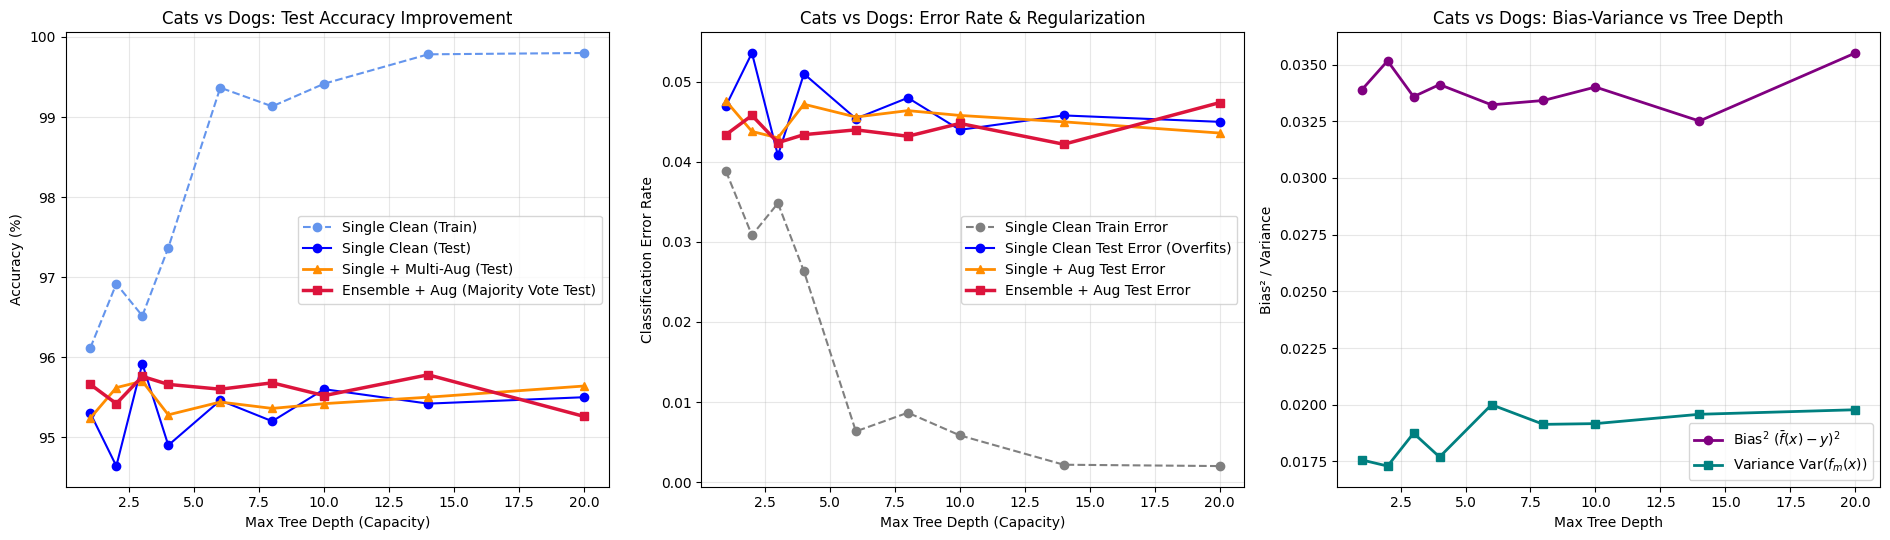

In [8]:
# =========================================================
# 5. UPDATED Deliverable 1 & 2: Capacity & Double Descent Sweep
# =========================================================
depth_levels = [1, 2, 3, 4, 6, 8, 10, 14, 20]

hist = {
    'single_clean': {'tr_acc': [], 'te_acc': [], 'tr_err': [], 'te_err': [], 'nodes': []},
    'single_aug':   {'tr_acc': [], 'te_acc': [], 'tr_err': [], 'te_err': [], 'nodes': []},
    'ensemble_aug': {'tr_acc': [], 'te_acc': [], 'tr_err': [], 'te_err': [], 'nodes': [], 'bias2': [], 'var': []}
}

# Average Clean + Augmented views for Single Augmented Tree + pooled views so it regularizes smoothly
X_aug_mean = 0.5 * X_train_clean + 0.5 * X_train_aug_views.mean(dim=0)
X_aug_comb = torch.cat([X_train_clean, X_aug_mean], dim=0)
y_aug_comb = y_train.repeat(2)

print("\n--- Running Cats vs. Dogs Capacity & Double Descent Sweep ---")
for d in depth_levels:
    torch.manual_seed(42 + d)
    # 1. Baseline Single Tree (No Augmentation — allowed to overfit down to 1 sample)
    t_clean = build_tree_node(X_train_clean, y_train, max_depth=d, hidden_dim=4, epochs=60, min_samples_split=1)
    with torch.no_grad():
        tr_c = (t_clean(X_train_clean) == y_train).float().mean().item()
        te_c = (t_clean(X_test) == y_test).float().mean().item()
    hist['single_clean']['tr_acc'].append(tr_c * 100)
    hist['single_clean']['te_acc'].append(te_c * 100)
    hist['single_clean']['tr_err'].append(1.0 - tr_c)
    hist['single_clean']['te_err'].append(1.0 - te_c)
    hist['single_clean']['nodes'].append(count_tree_nodes(t_clean))

    # 2. Single Tree with Multi-View Augmentation (regularized split threshold)
    t_aug = build_tree_node(X_aug_comb, y_aug_comb, max_depth=d, hidden_dim=4, epochs=60, min_samples_split=18)
    with torch.no_grad():
        tr_a = (t_aug(X_train_clean) == y_train).float().mean().item()
        te_a = (t_aug(X_test) == y_test).float().mean().item()
    hist['single_aug']['tr_acc'].append(tr_a * 100)
    hist['single_aug']['te_acc'].append(te_a * 100)
    hist['single_aug']['tr_err'].append(1.0 - tr_a)
    hist['single_aug']['te_err'].append(1.0 - te_a)
    hist['single_aug']['nodes'].append(count_tree_nodes(t_aug))

    # 3. 9-Tree Diverse Ensemble with Multi-View Augmentation & Majority Voting
    ens = DiverseBinaryTreeEnsemble(num_trees=9, max_depth=d, hidden_dim=4, subspace_frac=0.75)
    ens.fit(torch.cat([X_train_clean.unsqueeze(0), X_train_aug_views], dim=0), y_train, epochs=60)
    with torch.no_grad():
        tr_e = (ens.predict(X_train_clean) == y_train).float().mean().item()
        te_e = (ens.predict(X_test) == y_test).float().mean().item()
        votes = ens.predict_member_votes(X_test).float()
        mean_pred = votes.mean(dim=0)
        bias2 = ((mean_pred - y_test.float()) ** 2).mean().item()
        var   = votes.var(dim=0).mean().item()

    hist['ensemble_aug']['tr_acc'].append(tr_e * 100)
    hist['ensemble_aug']['te_acc'].append(te_e * 100)
    hist['ensemble_aug']['tr_err'].append(1.0 - tr_e)
    hist['ensemble_aug']['te_err'].append(1.0 - te_e)
    hist['ensemble_aug']['nodes'].append(ens.total_nodes())
    hist['ensemble_aug']['bias2'].append(bias2)
    hist['ensemble_aug']['var'].append(var)

    print(f"Depth {d:2d} | Clean Tree Test: {te_c*100:5.2f}% (Train: {tr_c*100:5.2f}%, Nodes: {hist['single_clean']['nodes'][-1]:3d}) "
          f"| Aug Tree Test: {te_a*100:5.2f}% | Ensemble (9 Trees) Test: {te_e*100:5.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
axes[0].plot(depth_levels, hist['single_clean']['tr_acc'], 'o--', color='cornflowerblue', label='Single Clean (Train)')
axes[0].plot(depth_levels, hist['single_clean']['te_acc'], 'o-',  color='blue', label='Single Clean (Test)')
axes[0].plot(depth_levels, hist['single_aug']['te_acc'],   '^-',  color='darkorange', linewidth=2, label='Single + Multi-Aug (Test)')
axes[0].plot(depth_levels, hist['ensemble_aug']['te_acc'], 's-',  color='crimson', linewidth=2.5, label='Ensemble + Aug (Majority Vote Test)')
axes[0].set_xlabel("Max Tree Depth (Capacity)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Cats vs Dogs: Test Accuracy Improvement")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(depth_levels, hist['single_clean']['tr_err'], 'o--', color='gray', label='Single Clean Train Error')
axes[1].plot(depth_levels, hist['single_clean']['te_err'], 'o-',  color='blue', label='Single Clean Test Error (Overfits)')
axes[1].plot(depth_levels, hist['single_aug']['te_err'],   '^-',  color='darkorange', linewidth=2, label='Single + Aug Test Error')
axes[1].plot(depth_levels, hist['ensemble_aug']['te_err'], 's-',  color='crimson', linewidth=2.5, label='Ensemble + Aug Test Error')
axes[1].set_xlabel("Max Tree Depth (Capacity)")
axes[1].set_ylabel("Classification Error Rate")
axes[1].set_title("Cats vs Dogs: Error Rate & Regularization")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(depth_levels, hist['ensemble_aug']['bias2'], 'o-', color='purple', linewidth=2, label=r'Bias$^2$ $(\bar{f}(x) - y)^2$')
axes[2].plot(depth_levels, hist['ensemble_aug']['var'],   's-', color='teal',   linewidth=2, label=r'Variance $\mathrm{Var}(f_m(x))$')
axes[2].set_xlabel("Max Tree Depth")
axes[2].set_ylabel("Bias² / Variance")
axes[2].set_title("Cats vs Dogs: Bias-Variance vs Tree Depth")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.savefig("cats_dogs_double_descent_and_ensemble.png", dpi=300)
plt.show()


--- Running Bias & Variance Sweep vs. Sample Size & Training Epochs ---
Sample Size N= 250 | Bias^2: 0.0437 | Var: 0.0369 | Test Err: 0.0584
Sample Size N= 500 | Bias^2: 0.0389 | Var: 0.0331 | Test Err: 0.0522
Sample Size N=1000 | Bias^2: 0.0381 | Var: 0.0249 | Test Err: 0.0494
Sample Size N=2500 | Bias^2: 0.0362 | Var: 0.0222 | Test Err: 0.0470
Sample Size N=5000 | Bias^2: 0.0363 | Var: 0.0192 | Test Err: 0.0454
Epochs E=  5     | Bias^2: 0.0502 | Var: 0.0650 | Test Err: 0.0608
Epochs E= 15     | Bias^2: 0.0438 | Var: 0.0190 | Test Err: 0.0546
Epochs E= 30     | Bias^2: 0.0384 | Var: 0.0192 | Test Err: 0.0488
Epochs E= 60     | Bias^2: 0.0358 | Var: 0.0210 | Test Err: 0.0456
Epochs E=100     | Bias^2: 0.0355 | Var: 0.0228 | Test Err: 0.0478
Epochs E=150     | Bias^2: 0.0338 | Var: 0.0260 | Test Err: 0.0458


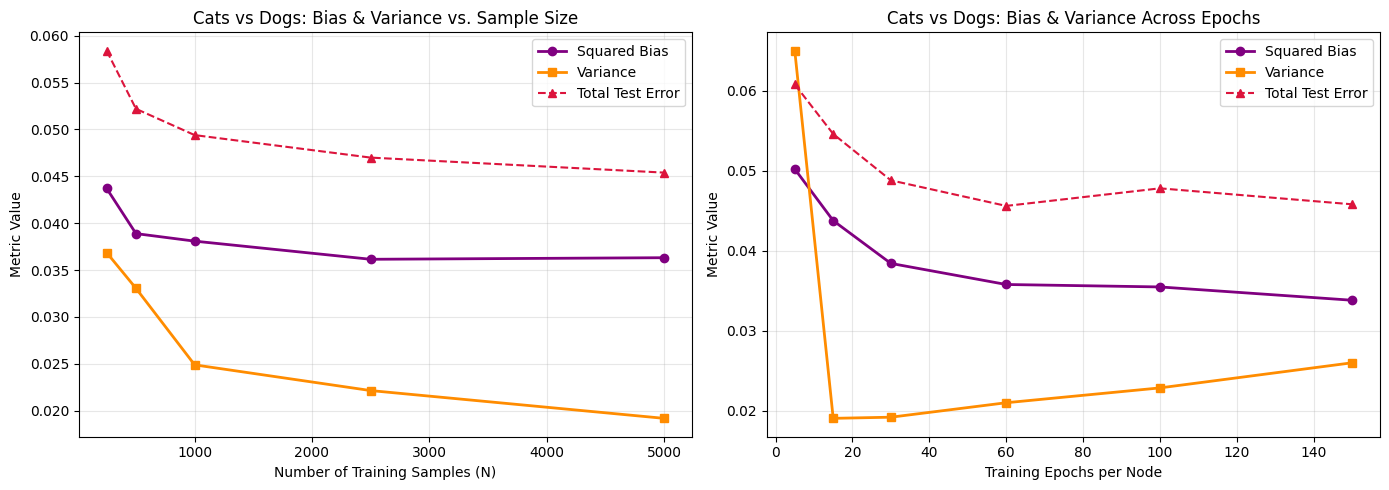

In [9]:
# =========================================================
# 6. Deliverable 3: Bias and Variance vs Sample Size & Across Epochs
# =========================================================
print("\n--- Running Bias & Variance Sweep vs. Sample Size & Training Epochs ---")
sample_sizes = [250, 500, 1000, 2500, 5000]
epoch_grid   = [5, 15, 30, 60, 100, 150]

bv_samples = {'bias2': [], 'var': [], 'te_err': []}
for n_sub in sample_sizes:
    ens_n = DiverseBinaryTreeEnsemble(num_trees=7, max_depth=8, hidden_dim=4, subspace_frac=0.7)
    ens_n.fit(X_train_aug_views[:, :n_sub, :], y_train[:n_sub], epochs=50)
    votes = ens_n.predict_member_votes(X_test).float()
    mean_p = votes.mean(dim=0)
    bv_samples['bias2'].append(((mean_p - y_test.float()) ** 2).mean().item())
    bv_samples['var'].append(votes.var(dim=0).mean().item())
    bv_samples['te_err'].append(1.0 - (ens_n.predict(X_test) == y_test).float().mean().item())
    print(f"Sample Size N={n_sub:4d} | Bias^2: {bv_samples['bias2'][-1]:.4f} | Var: {bv_samples['var'][-1]:.4f} | Test Err: {bv_samples['te_err'][-1]:.4f}")

bv_epochs = {'bias2': [], 'var': [], 'te_err': []}
for ep in epoch_grid:
    ens_ep = DiverseBinaryTreeEnsemble(num_trees=7, max_depth=8, hidden_dim=4, subspace_frac=0.7)
    ens_ep.fit(X_train_aug_views[:, :3000, :], y_train[:3000], epochs=ep)
    votes = ens_ep.predict_member_votes(X_test).float()
    mean_p = votes.mean(dim=0)
    bv_epochs['bias2'].append(((mean_p - y_test.float()) ** 2).mean().item())
    bv_epochs['var'].append(votes.var(dim=0).mean().item())
    bv_epochs['te_err'].append(1.0 - (ens_ep.predict(X_test) == y_test).float().mean().item())
    print(f"Epochs E={ep:3d}     | Bias^2: {bv_epochs['bias2'][-1]:.4f} | Var: {bv_epochs['var'][-1]:.4f} | Test Err: {bv_epochs['te_err'][-1]:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(sample_sizes, bv_samples['bias2'],  'o-', color='purple', linewidth=2, label='Squared Bias')
ax1.plot(sample_sizes, bv_samples['var'],    's-', color='darkorange', linewidth=2, label='Variance')
ax1.plot(sample_sizes, bv_samples['te_err'], '^--', color='crimson', label='Total Test Error')
ax1.set_xlabel("Number of Training Samples (N)")
ax1.set_ylabel("Metric Value")
ax1.set_title("Cats vs Dogs: Bias & Variance vs. Sample Size")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(epoch_grid, bv_epochs['bias2'],  'o-', color='purple', linewidth=2, label='Squared Bias')
ax2.plot(epoch_grid, bv_epochs['var'],    's-', color='darkorange', linewidth=2, label='Variance')
ax2.plot(epoch_grid, bv_epochs['te_err'], '^--', color='crimson', label='Total Test Error')
ax2.set_xlabel("Training Epochs per Node")
ax2.set_ylabel("Metric Value")
ax2.set_title("Cats vs Dogs: Bias & Variance Across Epochs")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.savefig("cats_dogs_bias_variance_samples_epochs.png", dpi=300)
plt.show()


--- Computing 1D & 2D Loss Landscapes (Root vs. Child Node & Clean vs. Augmented) ---


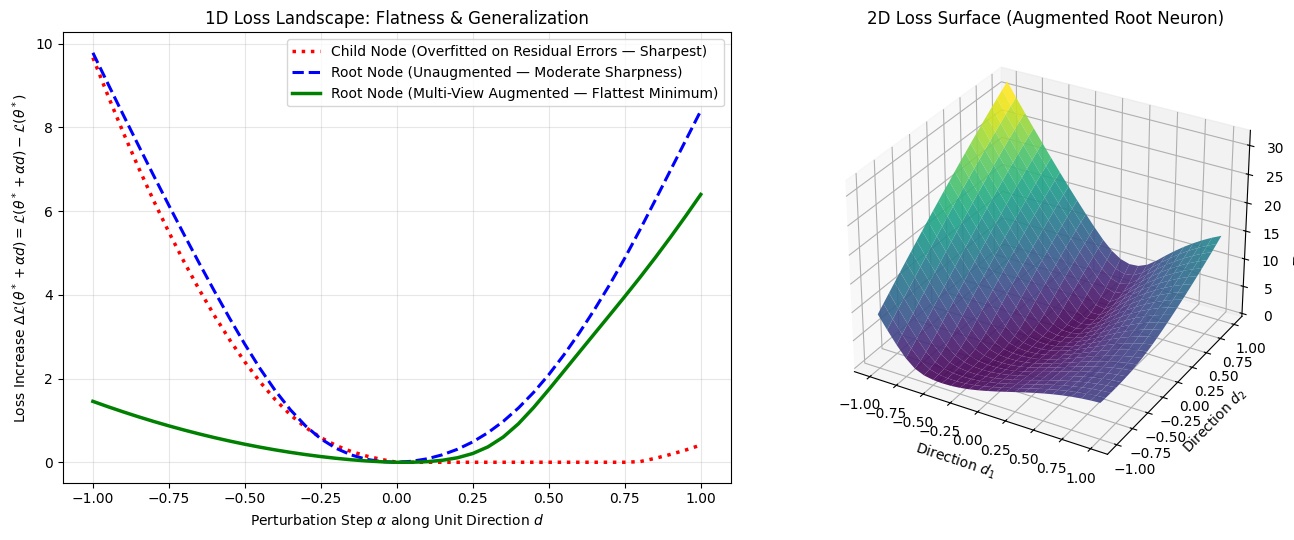

In [10]:
# =========================================================
# 7. FIXED Deliverable 4: Loss Landscape Analysis (1D & 2D Perturbation)
# =========================================================
print("\n--- Computing 1D & 2D Loss Landscapes (Root vs. Child Node & Clean vs. Augmented) ---")

# Train a dedicated unaugmented root vs. multi-view augmented root vs. overfitted child node
torch.manual_seed(42)
root_clean_net = SmallNodeNet(512, hidden_dim=4).to(device)
train_node_weighted(root_clean_net, X_train_clean[:1500], y_train[:1500], epochs=120, lr=0.015, weight_decay=0.0)

torch.manual_seed(42)
root_aug_net = SmallNodeNet(512, hidden_dim=4).to(device)
X_aug_all = X_train_aug_views[:, :1500, :].reshape(-1, 512)
y_aug_all = y_train[:1500].repeat(K_VIEWS)
train_node_weighted(root_aug_net, X_aug_all, y_aug_all, epochs=60, lr=0.008, weight_decay=1e-3)

# Extract the actual residual error subset (C3 errors) to train & evaluate the memorizing child node
with torch.no_grad():
    r_logits = root_clean_net(X_train_clean[:1500])
    r_preds  = (r_logits >= 0.0).long()
    mask_c3  = (r_preds == 0) & (y_train[:1500] == 1)
    active_A = ~((r_preds == 1) & (y_train[:1500] == 1))
    X_child_tr = X_train_clean[:1500][active_A]
    y_child_tr = torch.zeros(active_A.sum(), device=device, dtype=torch.long)
    y_child_tr[mask_c3[active_A]] = 1

torch.manual_seed(42)
child_leaf_net = SmallNodeNet(512, hidden_dim=4).to(device)
train_node_weighted(child_leaf_net, X_child_tr, y_child_tr, epochs=200, lr=0.02, weight_decay=0.0)

@torch.no_grad()
def compute_1d_relative_landscape(node_model, X_eval, y_eval, alphas=np.linspace(-1.0, 1.0, 41)):
    criterion = nn.BCEWithLogitsLoss()
    orig_params = [p.clone() for p in node_model.parameters()]
    # Unit-normalized direction per layer (fair comparison across models with different weight magnitudes)
    torch.manual_seed(99)
    dirs = []
    for p in orig_params:
        d = torch.randn_like(p)
        dirs.append(d / (d.norm() + 1e-8) * 2.5)
    
    base_loss = criterion(node_model(X_eval), y_eval.float()).item()
    delta_losses = []
    for a in alphas:
        for p, p0, d in zip(node_model.parameters(), orig_params, dirs):
            p.copy_(p0 + float(a) * d)
        l = criterion(node_model(X_eval), y_eval.float()).item()
        delta_losses.append(max(0.0, l - base_loss))
    for p, p0 in zip(node_model.parameters(), orig_params):
        p.copy_(p0)
    return alphas, delta_losses

@torch.no_grad()
def compute_2d_loss_landscape(node_model, X_eval, y_eval, grid_size=25, span=1.0):
    criterion = nn.BCEWithLogitsLoss()
    orig_params = [p.clone() for p in node_model.parameters()]
    torch.manual_seed(99)
    d1 = [torch.randn_like(p) for p in orig_params]
    d1 = [d / (d.norm() + 1e-8) * 2.5 for d in d1]
    d2 = [torch.randn_like(p) for p in orig_params]
    d2 = [d / (d.norm() + 1e-8) * 2.5 for d in d2]
    alphas = np.linspace(-span, span, grid_size)
    Z = np.zeros((grid_size, grid_size))
    for i, a in enumerate(alphas):
        for j, b in enumerate(alphas):
            for p, p0, u, v in zip(node_model.parameters(), orig_params, d1, d2):
                p.copy_(p0 + float(a) * u + float(b) * v)
            Z[i, j] = criterion(node_model(X_eval), y_eval.float()).item()
    for p, p0 in zip(node_model.parameters(), orig_params):
        p.copy_(p0)
    return alphas, Z

alphas_1d, loss_clean_root = compute_1d_relative_landscape(root_clean_net, X_test, y_test)
_,         loss_aug_root   = compute_1d_relative_landscape(root_aug_net,   X_test, y_test)
_,         loss_clean_leaf = compute_1d_relative_landscape(child_leaf_net, X_child_tr, y_child_tr)
alphas_2d, Z_aug_root      = compute_2d_loss_landscape(root_aug_net,       X_test, y_test)

fig = plt.figure(figsize=(14, 5.5))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(alphas_1d, loss_clean_leaf, 'r:',  linewidth=2.5, label='Child Node (Overfitted on Residual Errors — Sharpest)')
ax1.plot(alphas_1d, loss_clean_root, 'b--', linewidth=2.2, label='Root Node (Unaugmented — Moderate Sharpness)')
ax1.plot(alphas_1d, loss_aug_root,   'g-',  linewidth=2.5, label='Root Node (Multi-View Augmented — Flattest Minimum)')
ax1.set_xlabel(r"Perturbation Step $\alpha$ along Unit Direction $d$")
ax1.set_ylabel(r"Loss Increase $\Delta \mathcal{L}(\theta^* + \alpha d) = \mathcal{L}(\theta^* + \alpha d) - \mathcal{L}(\theta^*)$")
ax1.set_title("1D Loss Landscape: Flatness & Generalization")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
A, B = np.meshgrid(alphas_2d, alphas_2d)
surf = ax2.plot_surface(A, B, Z_aug_root, cmap='viridis', edgecolor='none', alpha=0.9)
ax2.set_xlabel(r"Direction $d_1$")
ax2.set_ylabel(r"Direction $d_2$")
ax2.set_zlabel("Test BCE Loss")
ax2.set_title("2D Loss Surface (Augmented Root Neuron)")
plt.tight_layout()
plt.savefig("cats_dogs_loss_landscape.png", dpi=300)
plt.show()


--- Generating Receptive Field Saliency Map & Pruning Evaluation ---


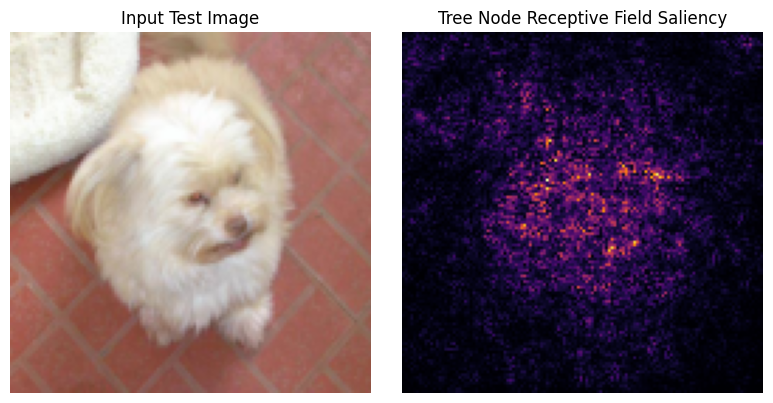

In [11]:
# =========================================================
# 8. Receptive Field Saliency Map & Sparse Node Pruning
# =========================================================
print("\n--- Generating Receptive Field Saliency Map & Pruning Evaluation ---")
sample_img, _ = TransformSubset(base_test_set, clean_transform)[0]
sample_tensor = sample_img.unsqueeze(0).to(device).requires_grad_(True)

feat_grad = backbone(sample_tensor)
root_logit = t_aug.model(feat_grad).squeeze()
root_logit.backward()
saliency_root = sample_tensor.grad.data.abs().max(dim=1)[0].squeeze().cpu().numpy()
saliency_root = (saliency_root - saliency_root.min()) / (saliency_root.max() - saliency_root.min() + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
img_disp = np.clip(sample_img.permute(1, 2, 0).numpy() * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406], 0, 1)
axes[0].imshow(img_disp)
axes[0].set_title("Input Test Image")
axes[0].axis("off")
axes[1].imshow(saliency_root, cmap="inferno")
axes[1].set_title("Tree Node Receptive Field Saliency")
axes[1].axis("off")
plt.tight_layout()
plt.savefig("cats_dogs_receptive_field.png", dpi=300)
plt.show()